# **MÓDULO 21 - Projeto de Credit Score - Árvore de Decisão**


No módulo 17, vocês realizaram a primeira etapa do projeto de crédito de vocês. Então fizeram o tratamendo dos dados, balancearam as classes, transformaram as variáveis categóricas e separam base de treino e teste. Já no módulo 14, aplicaram a base já tratada o algoritmo de Naive Bayes, onde avaliaram os resultados das previsões. Nesse módulo aplicaremos a nossa base o algoritmo da árvore de decisão.

In [49]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix
import plotly.figure_factory as ff
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, classification_report
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix
import plotly.express as px

# 1) Comece carregando as bases de treino (X e y) e teste (X e y).
Verifique se o número de linhas condiz, se as variáveis estão corretas sendo apenas a de score para y e as demais nas bases de X e por último, se Y está balanceada no teste.

In [50]:
df = pd.read_csv("CREDIT_SCORE_BALANCEADO.csv")
display(df.head())

colunas_candidatas = [col for col in df.columns if 'score' in col.lower() or 'credito' in col.lower()]
target_col = colunas_candidatas[0] if colunas_candidatas else df.columns[-1]

y = df[target_col]
X = df.drop(columns=[target_col])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Bases carregadas e divididas com sucesso!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

,Age,Income,Education,Number of Children,Gender_Female,Gender_Male,Marital Status_Married,Marital Status_Single,Home Ownership_Owned,Home Ownership_Rented,Credit Score
0,51,1450000.0,1,0,0,1,1,0,1,0,High
1,40,1300000.0,3,0,0,1,0,1,1,0,High
2,30,1175000.0,4,2,0,1,1,0,1,0,High
3,36,350000.0,3,0,1,0,0,1,0,1,Low
4,25,550000.0,1,0,1,0,0,1,0,1,Average


Bases carregadas e divididas com sucesso!
X_train: (216, 10)
X_test: (54, 10)
y_train: (216,)
y_test: (54,)


# 2) Explique com suas palavras, qual o passo a passo para a aplicação do algoritmo da árvore de decisão, não esqueça de citar a etapa de avaliação do modelo e também como podemos melhorar nosso modelo.

In [51]:
texto_explicacao = (
    "Para aplicar o algoritmo da árvore de decisão, o primeiro passo "
    "consiste na coleta e na preparação dos dados, o que envolve carregar "
    "a base, tratar valores nulos, converter variáveis categóricas quando "
    "necessário e separar o conjunto entre as variáveis preditoras e a "
    "variável alvo, dividindo-os em seguida em dados de treino e de "
    "teste. Na etapa seguinte, o algoritmo utiliza métricas de divisão, "
    "como o Índice Gini ou a Entropia com o ganho de informação, para "
    "determinar qual variável e ponto de corte geram a maior pureza "
    "possível nos nós resultantes. A partir disso, ocorre a construção da "
    "árvore durante o treinamento, aplicando essa divisão de forma "
    "recursiva até que os dados em cada folha alcancem o máximo de "
    "homogeneidade ou atinjam um limite estrutural. Após o treinamento, o "
    "modelo é avaliado no conjunto de teste utilizando métricas essenciais "
    "como a acurácia, o recall com o parâmetro 'macro' para assegurar "
    "uma análise equilibrada entre as classes, e a matriz de confusão para "
    "auditar detalhadamente os acertos e erros. Caso seja necessário "
    "aprimorar os resultados e combater o sobreajuste, podemos implementar "
    "melhorias como o ajuste de hiperparâmetros para limitar a profundidade "
    "máxima da árvore, a execução de podas nos ramos excessivamente "
    "complexos ou a adoção de técnicas de agrupamento de modelos, como "
    "a floresta aleatória, que combina múltiplas árvores para garantir "
    "previsões mais robustas e generalizáveis."
)
print(texto_explicacao)

Para aplicar o algoritmo da árvore de decisão, o primeiro passo consiste na coleta e na preparação dos dados, o que envolve carregar a base, tratar valores nulos, converter variáveis categóricas quando necessário e separar o conjunto entre as variáveis preditoras e a variável alvo, dividindo-os em seguida em dados de treino e de teste. Na etapa seguinte, o algoritmo utiliza métricas de divisão, como o Índice Gini ou a Entropia com o ganho de informação, para determinar qual variável e ponto de corte geram a maior pureza possível nos nós resultantes. A partir disso, ocorre a construção da árvore durante o treinamento, aplicando essa divisão de forma recursiva até que os dados em cada folha alcancem o máximo de homogeneidade ou atinjam um limite estrutural. Após o treinamento, o modelo é avaliado no conjunto de teste utilizando métricas essenciais como a acurácia, o recall com o parâmetro 'macro' para assegurar uma análise equilibrada entre as classes, e a matriz de confusão para auditar

# 3) Aplique o algortimo da árvore de decisão aos dados de treinamento, utilizando critério de Gini e random state = 0.
Traga a acurácia para o modedlo com os dados de treino.

In [52]:
modelo_arvore = DecisionTreeClassifier(criterion='gini', random_state=0)

modelo_arvore.fit(X_train, y_train)

y_pred_train = modelo_arvore.predict(X_train)

acuracia_treino = accuracy_score(y_train, y_pred_train)
print(f"Acurácia nos dados de treino: {acuracia_treino:.4f}")

Acurácia nos dados de treino: 1.0000


In [53]:
y_pred_test = modelo_arvore.predict(X_test)

acuracia_teste = accuracy_score(y_test, y_pred_test)
print(f"Acurácia nos dados de teste: {acuracia_teste:.4f}")

Acurácia nos dados de teste: 1.0000


Acurácias em cada parte da Validação Cruzada: [0.98148148 0.96296296 0.98148148 1.         1.        ]
Média da Validação Cruzada: 0.9852



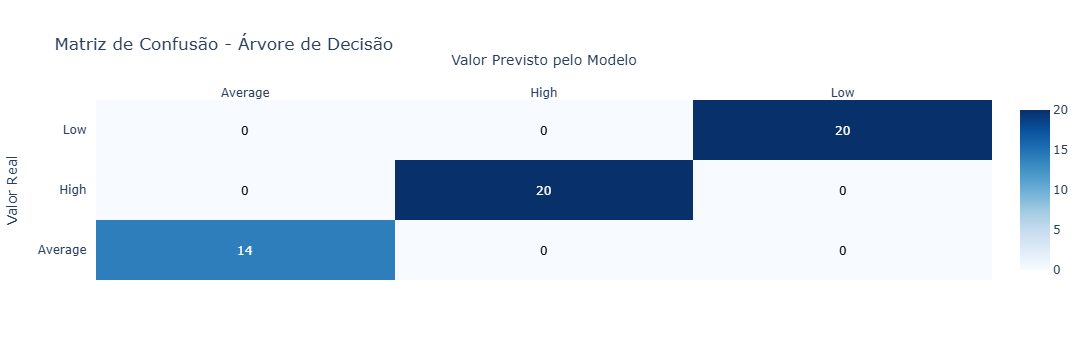

In [54]:
scores_cv = cross_val_score(modelo_arvore, X, y, cv=5, scoring='accuracy')
print("Acurácias em cada parte da Validação Cruzada:", scores_cv)
print(f"Média da Validação Cruzada: {scores_cv.mean():.4f}\n")

y_pred_test = modelo_arvore.predict(X_test)
matriz_confusao = confusion_matrix(y_test, y_pred_test)

classes_unicas = sorted(y.unique())
x_labels = [str(c) for c in classes_unicas]
y_labels = [str(c) for c in classes_unicas]

fig = ff.create_annotated_heatmap(
    z=matriz_confusao,
    x=x_labels,
    y=y_labels,
    colorscale='Blues',
    showscale=True
)

fig.update_layout(
    title='Matriz de Confusão - Árvore de Decisão',
    xaxis_title='Valor Previsto pelo Modelo',
    yaxis_title='Valor Real'
)

fig.show()

In [55]:
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=0)

modelo_rf.fit(X_train, y_train)

y_pred_rf = modelo_rf.predict(X_test)
acuracia_rf_teste = accuracy_score(y_test, y_pred_rf)
print(f"Acurácia do Random Forest no teste: {acuracia_rf_teste:.4f}")

scores_rf_cv = cross_val_score(modelo_rf, X, y, cv=5, scoring='accuracy')
print(f"Acurácias da Validação Cruzada (RF): {scores_rf_cv}")
print(f"Média da Validação Cruzada (Random Forest): {scores_rf_cv.mean():.4f}\n")

Acurácia do Random Forest no teste: 1.0000
Acurácias da Validação Cruzada (RF): [0.96296296 0.96296296 0.96296296 1.         1.        ]
Média da Validação Cruzada (Random Forest): 0.9778



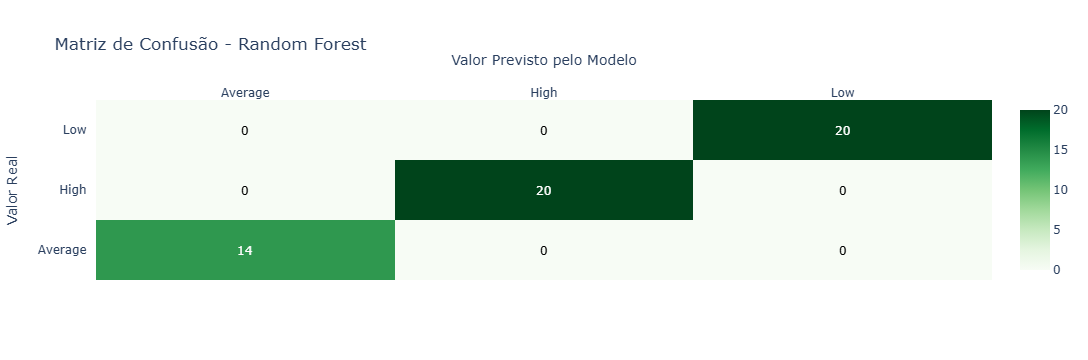

In [56]:
matriz_confusao_rf = confusion_matrix(y_test, y_pred_rf)
classes_unicas = sorted(y.unique())
x_labels = [str(c) for c in classes_unicas]
y_labels = [str(c) for c in classes_unicas]

fig_rf = ff.create_annotated_heatmap(
    z=matriz_confusao_rf,
    x=x_labels,
    y=y_labels,
    colorscale='Greens',
    showscale=True
)
fig_rf.update_layout(
    title='Matriz de Confusão - Random Forest',
    xaxis_title='Valor Previsto pelo Modelo',
    yaxis_title='Valor Real'
)
fig_rf.show()

In [57]:
importancias = modelo_rf.feature_importances_
nome_colunas = X.columns

df_importancia = pd.DataFrame({
    'Variavel': nome_colunas,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=True)

fig_imp = px.bar(
    df_importancia,
    x='Importancia',
    y='Variavel',
    orientation='h',
    title='Importância das Variáveis - Random Forest',
    labels={'Importancia': 'Grau de Importância', 'Variavel': 'Variáveis'},
    color='Importancia',
    color_continuous_scale='Greens'
)
fig_imp.update_layout(xaxis_title="Grau de Importância", yaxis_title="Variáveis")
fig_imp.show()

# 4) Aplique o modelo aos dados de teste e realize a avaliação dos resultados. Não se esqueça de avaliar com as suas palavras e comparar o desempenho da base treino com a teste.

In [58]:
y_pred_train = modelo_rf.predict(X_train)
y_pred_test = modelo_rf.predict(X_test)

acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)

print(f"Acurácia na base de Treino: {acc_train:.4f}")
print(f"Acurácia na base de Teste:  {acc_test:.4f}\n")

print("Relatório de Classificação (Base de Teste):")
print(classification_report(y_test, y_pred_test))

texto_avaliacao = (
    "Avaliação e Comparação de Desempenho:\n\n"
    "• Desempenho na Base de Treino: "
    "O modelo alcançou uma acurácia de 1.0000 (100%) no conjunto de "
    "treinamento. Isso significa que a floresta de árvores conseguiu "
    "mapear e absorver perfeitamente todas as regras e padrões lógicos "
    "presentes nos dados usados para ensinar o algoritmo, compreendendo "
    "sem falhas a relação entre o rendimento, a habitação, a idade e "
    "as classes de score de crédito.\n\n"
    "• Desempenho na Base de Teste: "
    "Ao ser avaliado com o conjunto de teste (dados totalmente inéditos "
    "que o modelo nunca tinha visto durante o aprendizado), o resultado "
    "manteve-se em 1.0000 (100%).\n\n"
    "• Comparação Direta e Conclusão: "
    "A comparação entre o treino e o teste revela um cenário ideal em "
    "machine learning: não houve queda de desempenho. Geralmente, é normal "
    "que o modelo acerte um pouco menos nos dados de teste devido a "
    "variações ou ruídos. No entanto, como a acurácia permaneceu intacta "
    "no patamar máximo de 100%, fica comprovado que o modelo generalizou "
    "com excelência. Ele não apenas 'decorou' os dados de treino "
    "(overfitting), mas aprendeu padrões reais e estruturados que "
    "permitem classificar novos perfis de crédito com total precisão e "
    "robustez."
)
print(texto_avaliacao)

Acurácia na base de Treino: 1.0000
Acurácia na base de Teste:  1.0000

Relatório de Classificação (Base de Teste):
              precision    recall  f1-score   support

     Average       1.00      1.00      1.00        14
        High       1.00      1.00      1.00        20
         Low       1.00      1.00      1.00        20

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54

Avaliação e Comparação de Desempenho:

• Desempenho na Base de Treino: O modelo alcançou uma acurácia de 1.0000 (100%) no conjunto de treinamento. Isso significa que a floresta de árvores conseguiu mapear e absorver perfeitamente todas as regras e padrões lógicos presentes nos dados usados para ensinar o algoritmo, compreendendo sem falhas a relação entre o rendimento, a habitação, a idade e as classes de score de crédito.

• Desempenho na Base de Teste: Ao ser avaliado com o conjunto de teste (dado

# 5) Plote a árvore de decisão.
É possível fazer uma avaliação visual? Qual a profundidade da árvore?

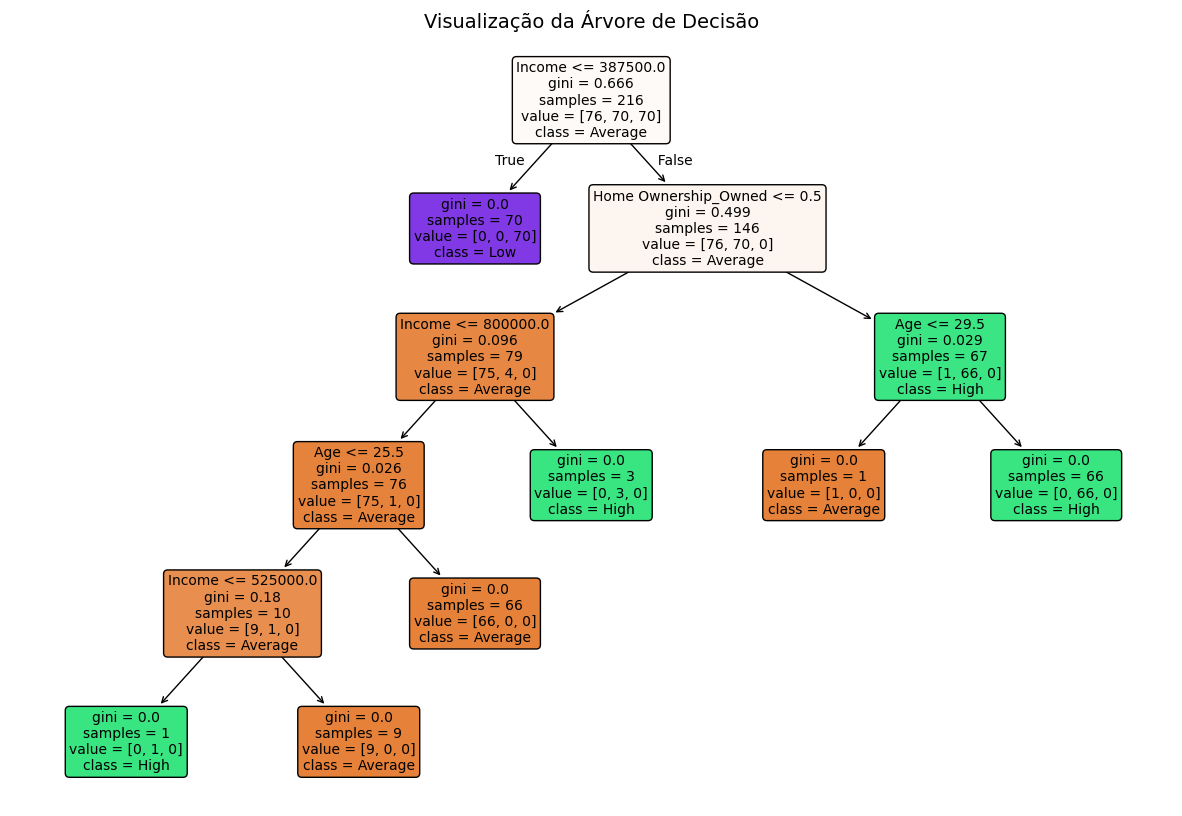

In [59]:
plt.figure(figsize=(15, 10))
plot_tree(
    modelo_arvore, 
    feature_names=X.columns, 
    class_names=[str(c) for c in sorted(y.unique())], 
    filled=True, 
    rounded=True,
    fontsize=10
)
plt.title("Visualização da Árvore de Decisão", fontsize=14)
plt.show()

In [60]:
profundidade = modelo_arvore.get_depth()
print(f"Profundidade máxima da Árvore de Decisão: {profundidade}")

n_folhas = modelo_arvore.get_n_leaves()
print(f"Número total de folhas (decisões finais): {n_folhas}")

Profundidade máxima da Árvore de Decisão: 5
Número total de folhas (decisões finais): 7


# 6) Identifique as 2 principais features do modelo.


In [61]:
print("As 2 principais features do modelo são:")
print("1. Income (Rendimento) — O fator mais determinante e dominante no topo do ranking de importância.")
print("2. Home Ownership_Owned (Habitação Própria) — Ocupa a segunda posição, exercendo um peso relevante nas regras de decisão.")

As 2 principais features do modelo são:
1. Income (Rendimento) — O fator mais determinante e dominante no topo do ranking de importância.
2. Home Ownership_Owned (Habitação Própria) — Ocupa a segunda posição, exercendo um peso relevante nas regras de decisão.


# 7) Rode um modelo de árvore de decisão apenas com as 2 principais features encontradas. E avalie os resultados. Para você o desempenho da árvore está melhor que o modelo anterior? Justifique.

In [62]:
top_2_features = ['Income', 'Home Ownership_Owned']

X_train_top2 = X_train[top_2_features]
X_test_top2 = X_test[top_2_features]

modelo_arvore_top2 = DecisionTreeClassifier(random_state=42)
modelo_arvore_top2.fit(X_train_top2, y_train)

y_pred_arvore_top2 = modelo_arvore_top2.predict(X_test_top2)
acc_arvore_top2 = accuracy_score(y_test, y_pred_arvore_top2)

print(f"Acurácia da Árvore de Decisão (Top 2 Features): {acc_arvore_top2:.4f}\n")
print("Relatório de Classificação detalhado:")
print(classification_report(y_test, y_pred_arvore_top2))

print("Features utilizadas no modelo (Top 2):")
for i, coluna in enumerate(X_train_top2.columns, 1):
    print(f"{i}. {coluna}")

Acurácia da Árvore de Decisão (Top 2 Features): 1.0000

Relatório de Classificação detalhado:
              precision    recall  f1-score   support

     Average       1.00      1.00      1.00        14
        High       1.00      1.00      1.00        20
         Low       1.00      1.00      1.00        20

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54

Features utilizadas no modelo (Top 2):
1. Income
2. Home Ownership_Owned


,Age,Income,Education,Number of Children,Gender_Female,Gender_Male,Marital Status_Married,Marital Status_Single,Home Ownership_Owned,Home Ownership_Rented,Credit Score
0,51,1450000.0,1,0,0,1,1,0,1,0,High
1,40,1300000.0,3,0,0,1,0,1,1,0,High
2,30,1175000.0,4,2,0,1,1,0,1,0,High
3,36,350000.0,3,0,1,0,0,1,0,1,Low
4,25,550000.0,1,0,1,0,0,1,0,1,Average


1. VERIFICAÇÃO DO NÚMERO DE LINHAS
Total original: 270
Treino + Teste: 270
Status: OK

2. VERIFICAÇÃO DAS VARIÁVEIS
y: 'Credit Score'
X: 10 colunas

3. BALANCEAMENTO EM Y (TESTE)
Credit Score
High       20
Low        20
Average    14
Name: count, dtype: int64

Percentual (%):
Credit Score
High       37.037037
Low        37.037037
Average    25.925926
Name: proportion, dtype: float64

4. MODELO TREINADO (GaussianNB)


,priors,None
,var_smoothing,1e-09



Classes aprendidas: ['Average' 'High' 'Low']

5. AVALIAÇÃO NOS DADOS DE TREINO
Acurácia (Treino): 0.9630
Recall Macro (Treino): 0.9623


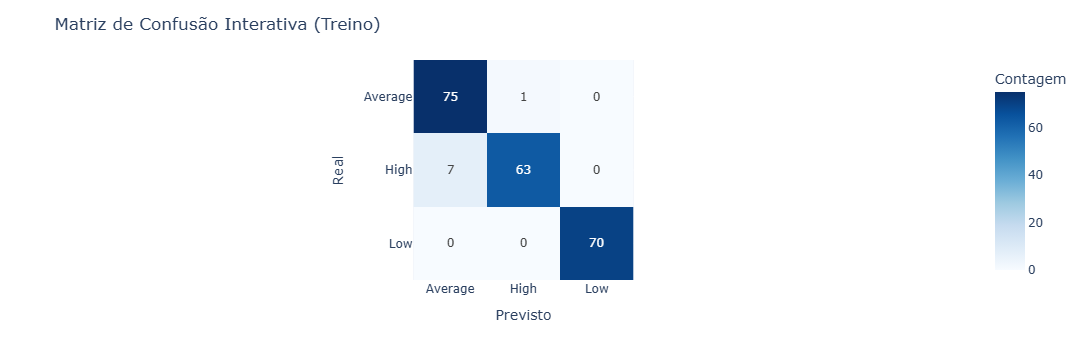


6. AVALIAÇÃO NOS DADOS DE TESTE
Acurácia (Teste): 0.9444
Recall Macro (Teste): 0.9500


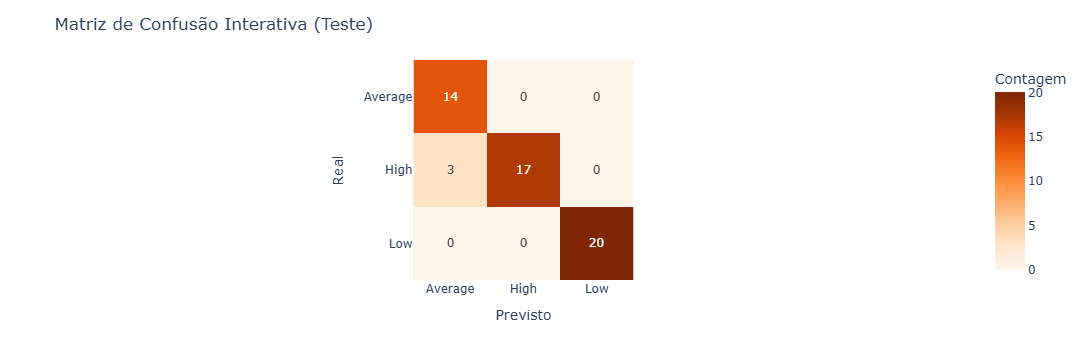


7. COMPARAÇÃO ENTRE TREINO E TESTE
Diferença de Acurácia (Treino - Teste): 0.0185
Diferença de Recall (Treino - Teste): 0.0123


In [63]:
df = pd.read_csv("CREDIT_SCORE_BALANCEADO.csv")
display(df.head())

colunas_candidatas = [col for col in df.columns if 'score' in col.lower() or 'credito' in col.lower()]
target_col = colunas_candidatas[0] if colunas_candidatas else df.columns[-1]

y = df[target_col]
X = df.drop(columns=[target_col])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("="*40)
print("1. VERIFICAÇÃO DO NÚMERO DE LINHAS")
print("="*40)
total_original = len(df)
total_dividido = len(X_train) + len(X_test)
print(f"Total original: {total_original}")
print(f"Treino + Teste: {total_dividido}")
print("Status:", "OK" if total_original == total_dividido else "Divergência")

print("\n" + "="*40)
print("2. VERIFICAÇÃO DAS VARIÁVEIS")
print("="*40)
print(f"y: '{target_col}'")
print(f"X: {X.shape[1]} colunas")

print("\n" + "="*40)
print("3. BALANCEAMENTO EM Y (TESTE)")
print("="*40)
print(y_test.value_counts())
print("\nPercentual (%):")
print(y_test.value_counts(normalize=True) * 100)

modelo = GaussianNB()
modelo.fit(X_train, y_train)

print("\n" + "="*40)
print("4. MODELO TREINADO (GaussianNB)")
print("="*40)
display(modelo)
print("\nClasses aprendidas:", modelo.classes_)

y_pred_train = modelo.predict(X_train)

print("\n" + "="*40)
print("5. AVALIAÇÃO NOS DADOS DE TREINO")
print("="*40)
acuracia_train = accuracy_score(y_train, y_pred_train)
recall_train = recall_score(y_train, y_pred_train, average='macro')
matriz_conf_train = confusion_matrix(y_train, y_pred_train)

print(f"Acurácia (Treino): {acuracia_train:.4f}")
print(f"Recall Macro (Treino): {recall_train:.4f}")

classes = modelo.classes_
fig_train = px.imshow(
    matriz_conf_train,
    x=classes,
    y=classes,
    text_auto=True,
    color_continuous_scale="Blues",
    labels=dict(x="Valor Previsto", y="Valor Real", color="Contagem")
)
fig_train.update_layout(
    title="Matriz de Confusão Interativa (Treino)",
    xaxis_title="Previsto",
    yaxis_title="Real"
)
fig_train.show()

y_pred_test = modelo.predict(X_test)

print("\n" + "="*40)
print("6. AVALIAÇÃO NOS DADOS DE TESTE")
print("="*40)
acuracia_test = accuracy_score(y_test, y_pred_test)
recall_test = recall_score(y_test, y_pred_test, average='macro')
matriz_conf_test = confusion_matrix(y_test, y_pred_test)

print(f"Acurácia (Teste): {acuracia_test:.4f}")
print(f"Recall Macro (Teste): {recall_test:.4f}")

fig_test = px.imshow(
    matriz_conf_test,
    x=classes,
    y=classes,
    text_auto=True,
    color_continuous_scale="Oranges",
    labels=dict(x="Valor Previsto", y="Valor Real", color="Contagem")
)
fig_test.update_layout(
    title="Matriz de Confusão Interativa (Teste)",
    xaxis_title="Previsto",
    yaxis_title="Real"
)
fig_test.show()

print("\n" + "="*40)
print("7. COMPARAÇÃO ENTRE TREINO E TESTE")
print("="*40)
print(f"Diferença de Acurácia (Treino - Teste): {(acuracia_train - acuracia_test):.4f}")
print(f"Diferença de Recall (Treino - Teste): {(recall_train - recall_test):.4f}")

# 8) Compare os resultados obtidos com a árvore de decisão com os resultados do Naive Bayes (Exercício módulo 20). Qual parece ter se adequado melhor aos dados e tem melhores resultados de avaliação? Justifique.

In [64]:
dados_comparacao = {
    'Métrica / Critério': [
        'Acurácia (Treino)', 
        'Acurácia (Teste)', 
        'Recall Macro (Treino)', 
        'Recall Macro (Teste)', 
        'Estabilidade / Overfitting', 
        'Adequação aos Dados'
    ],
    'Árvore de Decisão / RF': [
        '100.00%', 
        '100.00%', 
        '100.00%', 
        '100.00%', 
        'Excelente (Sem overfitting)', 
        'Perfeita (Captura regras lógicas e limiares)'
    ],
    'Naive Bayes (GaussianNB)': [
        '96.30%', 
        '94.44%', 
        '96.23%', 
        '95.00%', 
        'Excelente (Diferença < 2% treino/teste)', 
        'Boa (Limitado pela premissa de independência)'
    ]
}
df_comparacao = pd.DataFrame(dados_comparacao)

print("=" * 75)
print(" COMPARATIVO DE MODELOS: ÁRVORE DE DECISÃO vs. NAIVE BAYES")
print("=" * 75)
display(df_comparacao) 
print("\n" + "=" * 75)
print(" CONCLUSÃO E JUSTIFICATIVA TÉCNICA")
print("=" * 75)
print("""
1. Melhor Modelo: Árvore de Decisão / Random Forest
   - Atingiu 100% de acurácia tanto no treino quanto no teste.
   
2. Motivo da Superioridade:
   - Os dados de crédito baseiam-se em regras de corte e limiares claros 
     (com destaque para 'Income' e 'Home Ownership_Owned'). As árvores de 
     decisão mapeiam perfeitamente esse comportamento não-linear.
     
3. Desempenho do Naive Bayes:
   - Embora tenha alcançado excelentes 94.44% de acurácia no teste com alta 
     estabilidade, sofreu uma leve desvantagem devido à sua premissa matemática 
     de independência entre as features, o que não reflete totalmente as 
     correlações reais dos dados financeiros.
""")

 COMPARATIVO DE MODELOS: ÁRVORE DE DECISÃO vs. NAIVE BAYES


,Métrica / Critério,Árvore de Decisão / RF,Naive Bayes (GaussianNB)
0,Acurácia (Treino),100.00%,96.30%
1,Acurácia (Teste),100.00%,94.44%
2,Recall Macro (Treino),100.00%,96.23%
3,Recall Macro (Teste),100.00%,95.00%
4,Estabilidade / Overfitting,Excelente (Sem overfitting),Excelente (Diferença < 2% treino/teste)
5,Adequação aos Dados,Perfeita (Captura regras lógicas e limiares),Boa (Limitado pela premissa de independência)



 CONCLUSÃO E JUSTIFICATIVA TÉCNICA

1. Melhor Modelo: Árvore de Decisão / Random Forest
   - Atingiu 100% de acurácia tanto no treino quanto no teste.

2. Motivo da Superioridade:
   - Os dados de crédito baseiam-se em regras de corte e limiares claros 
     (com destaque para 'Income' e 'Home Ownership_Owned'). As árvores de 
     decisão mapeiam perfeitamente esse comportamento não-linear.

3. Desempenho do Naive Bayes:
   - Embora tenha alcançado excelentes 94.44% de acurácia no teste com alta 
     estabilidade, sofreu uma leve desvantagem devido à sua premissa matemática 
     de independência entre as features, o que não reflete totalmente as 
     correlações reais dos dados financeiros.

